# 4 · Calibrating Heston and Bates to market quotes, and CIR to the yield curve
1. **Validation:** calibrate to a synthetic surface generated from known parameters and check they are recovered.
2. **Market:** calibrate to a real SPY call surface (snapshot in `data/`, refreshable with `scripts/fetch_market_data.py`).
3. **Rates:** fit the CIR and Vasicek models to the US Treasury curve.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
from derivpricer import black_scholes as bs, heston, bates, calibration, rates

## 1. Parameter-recovery test

In [2]:
S0, r = 100.0, 0.04
true = heston.HestonParams(v0=0.05, kappa=1.5, theta=0.06, xi=0.6, rho=-0.65)
rng = np.random.default_rng(0)
rows = []
for T in (0.25, 0.5, 1.0, 2.0):
    k = np.linspace(80, 120, 9)
    px = heston.price(S0, k, T, r, true) * (1 + 0.002 * rng.standard_normal(k.size))  # 0.2% quote noise
    rows += list(zip(k, [T] * k.size, px))
synthetic = pd.DataFrame(rows, columns=["strike", "maturity", "price"])
res = calibration.calibrate_heston(S0, synthetic, r)
pd.DataFrame({"true": calibration.as_dict(true), "calibrated": calibration.as_dict(res.params)}).round(4).assign(rmse=res.rmse)

,true,calibrated,rmse
v0,0.05,0.0499,0.02001
kappa,1.50,1.5432,0.02001
theta,0.06,0.0594,0.02001
xi,0.60,0.5966,0.02001
rho,-0.65,-0.6540,0.02001


## 2. Calibration to the SPY option surface

In [3]:
snap = pd.read_csv("../data/spy_call_surface.csv")       # refresh: python scripts/fetch_market_data.py
S_mkt, src = snap.spot.iloc[0], f"SPY, as of {snap["asof"].iloc[0]}"
# ~12 strikes per expiry keeps calibration fast without losing the shape of the smile
quotes = (snap.groupby("expiry", group_keys=False).apply(lambda d: d.iloc[:: max(1, len(d) // 12)])
              [["strike", "maturity", "price"]].reset_index(drop=True))
r_mkt, q_mkt = 0.041, 0.013  # 3m T-bill yield and SPY dividend yield
print(src, "-", len(quotes), "quotes,", quotes.maturity.nunique(), "expiries")

# weight price errors by 1/vega so the fit is roughly uniform in implied-volatility terms
vega = bs.greeks(S_mkt, quotes.strike.values, quotes.maturity.values, r_mkt, 0.18, "call", q_mkt).vega
w = 1 / np.maximum(vega, 1.0)
h = calibration.calibrate_heston(S_mkt, quotes, r_mkt, q_mkt, weights=w)
b = calibration.calibrate_bates(S_mkt, quotes, r_mkt, q_mkt, x0=(*vars(h.params).values(), 0.3, -0.1, 0.1), weights=w)

def iv_rmse(model_px):
    err = [bs.implied_vol(m, S_mkt, k, T, r_mkt, q=q_mkt) - bs.implied_vol(p, S_mkt, k, T, r_mkt, q=q_mkt)
           for k, T, p, m in zip(quotes.strike, quotes.maturity, quotes.price, model_px)]
    return float(np.sqrt(np.nanmean(np.square(err))) * 100)

summary = {"Heston": {**calibration.as_dict(h.params), "price RMSE ($)": h.rmse, "IV RMSE (vol pts)": iv_rmse(h.model_prices)},
           "Bates": {**calibration.as_dict(b.params), "price RMSE ($)": b.rmse, "IV RMSE (vol pts)": iv_rmse(b.model_prices)}}
pd.DataFrame(summary).astype(float).round(4)

SPY, as of 2026-11-11 - 52 quotes, 4 expiries


,Heston,Bates
v0,0.0331,0.0267
kappa,0.7849,0.8620
theta,0.2500,0.2500
xi,1.9841,1.9977
rho,-0.7795,-0.9713
price RMSE ($),1.1824,1.0481
IV RMSE (vol pts),0.8919,0.7832
lam,NaN,3.0000
mu_j,NaN,0.0408
delta,NaN,0.0010


**Reading the result.** Short-dated index options have a steep skew, so Heston needs a high vol-of-vol (ξ) and a strongly negative ρ to match it. Bates adds jumps, which take up part of the short-maturity skew; with only four expiries (all under 8 months) the gain is modest. The jump parameters, and κ and θ separately, are loosely identified: short maturities pin down mainly the product κθ. A fit error under about one volatility point is good for a five-parameter model.

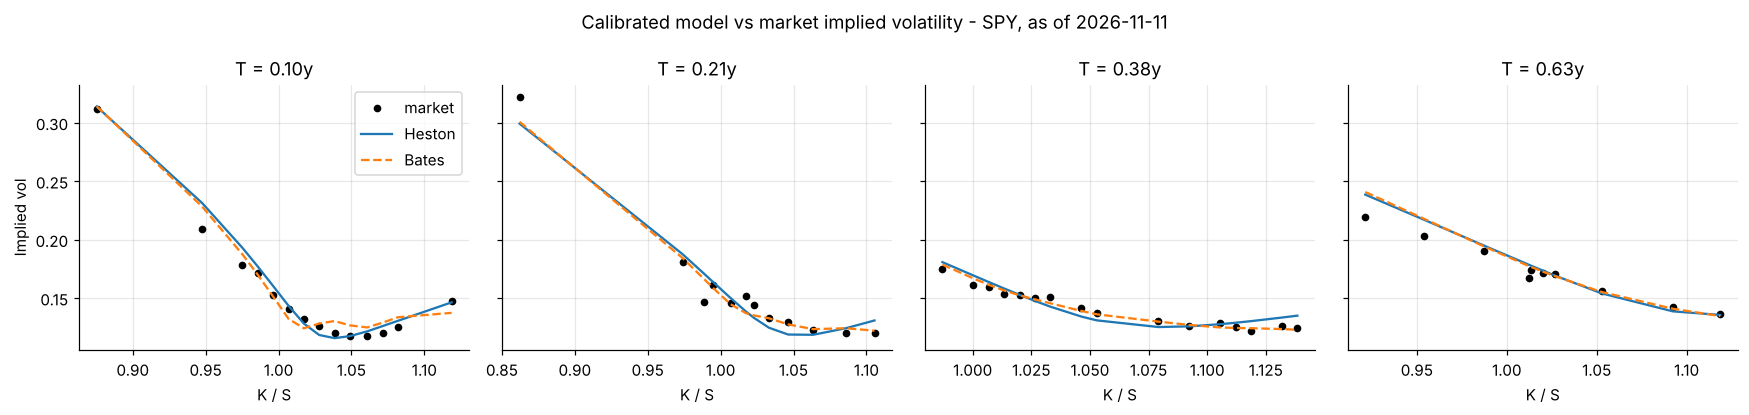

In [4]:
quotes = quotes.assign(heston=h.model_prices, bates=b.model_prices)
mats = sorted(quotes.maturity.unique())
fig, axes = plt.subplots(1, len(mats), figsize=(4 * len(mats), 3.8), sharey=True)
for ax, T in zip(np.atleast_1d(axes), mats):
    d = quotes[quotes.maturity == T]
    iv = lambda col: [bs.implied_vol(p, S_mkt, k, T, r_mkt, q=q_mkt) for k, p in zip(d.strike, d[col])]
    ax.plot(d.strike / S_mkt, iv("price"), "ko", ms=4, label="market")
    ax.plot(d.strike / S_mkt, iv("heston"), label="Heston"); ax.plot(d.strike / S_mkt, iv("bates"), "--", label="Bates")
    ax.set_title(f"T = {T:.2f}y"); ax.set_xlabel("K / S")
np.atleast_1d(axes)[0].set_ylabel("Implied vol"); np.atleast_1d(axes)[0].legend()
fig.suptitle(f"Calibrated model vs market implied volatility - {src}"); fig.tight_layout()
fig.savefig(IMG / "calibration_fit.png", bbox_inches="tight"); plt.show()

## 3. Short-rate models fitted to the Treasury curve

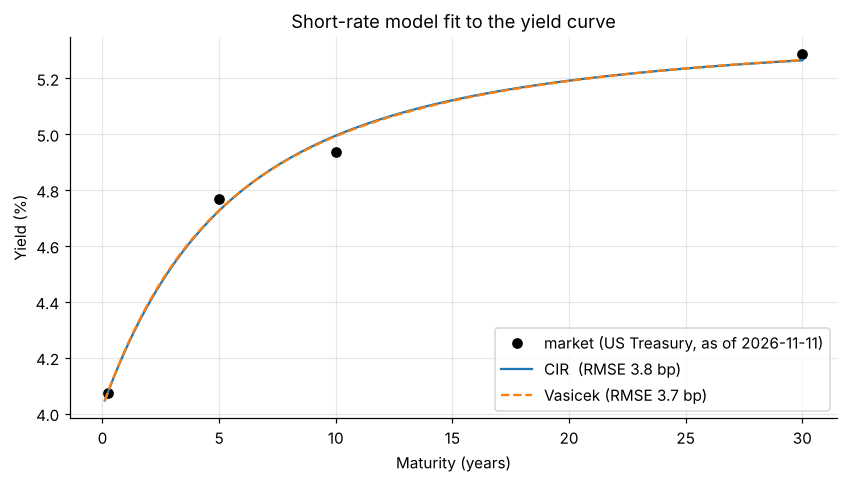

,CIR,Vasicek
r0,0.0402,0.0402
a,0.2033,0.2299
b,0.0629,0.0611
sigma,0.1249,0.0269


In [5]:
tc = pd.read_csv("../data/treasury_curve.csv")
curve, src_c = tc.set_index("maturity")["yield"], f"US Treasury, as of {tc["asof"].iloc[0]}"
# convert bond-equivalent yields to continuous compounding
cont = np.log(1 + curve / 2) * 2
cir_p, cir_err = rates.calibrate(cont.index, cont.values, "cir")
vas_p, vas_err = rates.calibrate(cont.index, cont.values, "vasicek")
grid = np.linspace(0.1, 30, 200)
plt.plot(cont.index, cont.values * 100, "ko", label=f"market ({src_c})")
plt.plot(grid, rates.zero_yield(rates.cir_zcb(grid, cir_p), grid) * 100, label=f"CIR  (RMSE {cir_err*1e4:.1f} bp)")
plt.plot(grid, rates.zero_yield(rates.vasicek_zcb(grid, vas_p), grid) * 100, "--", label=f"Vasicek (RMSE {vas_err*1e4:.1f} bp)")
plt.title("Short-rate model fit to the yield curve"); plt.xlabel("Maturity (years)"); plt.ylabel("Yield (%)"); plt.legend()
plt.savefig(IMG / "yield_curve_fit.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"CIR": vars(cir_p), "Vasicek": vars(vas_p)}).round(4)

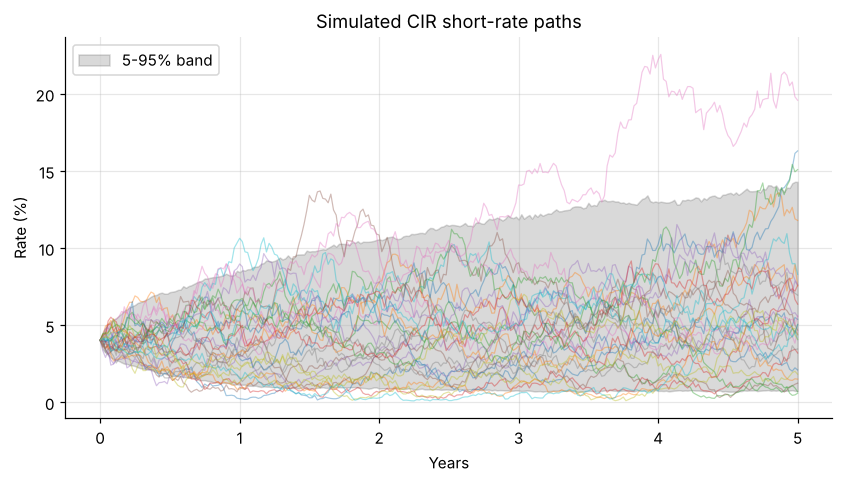

In [6]:
paths = rates.simulate_cir(cir_p, 5.0, n_steps=260, n_paths=2000)
t = np.linspace(0, 5, 261)
plt.plot(t, paths[:, :30] * 100, alpha=0.4, lw=0.8)
plt.fill_between(t, *np.percentile(paths, [5, 95], axis=1) * 100, alpha=0.15, color="k", label="5-95% band")
plt.title("Simulated CIR short-rate paths"); plt.xlabel("Years"); plt.ylabel("Rate (%)"); plt.legend(); plt.show()